[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DigitalPasts/alpcourse/blob/main/notebooks/05_Vector_Space_Model.ipynb)



# Woruldende: Eschatological Vocabulary in Old English Homilies

This notebook applies the vector space model approach described by
[Karsdorp et al. in "Exploring Texts using the Vector Space Model"](https://www.humanitiesdataanalysis.org/vector-space-model/notebook.html)
to a corpus of Old English homilies. The original notebook was developed
by Avital Romach for Akkadian and Egyptian corpora; this version was
substantially rewritten and adapted for Old English eschatological texts
as part of the Woruldende project.

By representing texts as numeric vectors capturing word frequencies, we
quantify lexical similarities and differences between three author groups:
Wulfstan of York, Ælfric of Eynsham, and the anonymous Blickling and
Vercelli homilists. The vector space model allows us to reason about texts
spatially, applying geometric concepts like cosine distance to assess how
"close" texts are based on shared vocabulary.

Texts are preprocessed by tokenizing, lemmatising using a 173-entry Old
English headword dictionary, and constructing a TF-IDF document-term
matrix. We then apply cosine distance measurement and t-SNE visualisation
to explore stylistic patterns across the corpus.

This notebook was adapted and developed by [Anonymous for review], with
methodological guidance from Shai Gordin and Eliese-Sophie Lincke
(co-authors). It should be cited accordingly (see citation information
at the bottom).

Note: author names will be restored in the final published version.

# Preprocessing the corpus

## Imports

In [ ]:
# ================================================================
# WORULDENDE — Notebook 5 Replacement Data v3
# 19 texts — expanded corpus
# ================================================================

import os
import pandas as pd
from google.colab import files

# ── STEP 1: UPLOAD YOUR FILES ────────────────────────────────
# Upload ALL of the following files at once:
#   - woruldende_metadata_v3.csv
#   - WHom_SermoLupi_A.csv, WHom_SermoLupi_B.csv
#   - WHom_Antichrist.csv, WHom_SignsDoom.csv
#   - BlHom_II.csv, BlHom_IV.csv, BlHom_V.csv
#   - BlHom_VII.csv, BlHom_X.csv, BlHom_XI.csv
#   - VHom_II.csv, VHom_IV.csv, VHom_V.csv, VHom_IX.csv
#   - BHH_CCCC303.csv
#   - AECHom_I.csv, AECHom_XV.csv, AECHom_XXI.csv, AECHom_XL.csv

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

# ── STEP 2: LOAD METADATA ────────────────────────────────────
metadata = pd.read_csv("woruldende_metadata_v3.csv", encoding="utf-8", index_col="text_id").fillna("")
print("\nMetadata loaded:")
print(metadata)

# ── STEP 3: LOAD CORPUS ──────────────────────────────────────
text_order = [
    "WHom_SermoLupi_A", "WHom_SermoLupi_B", "WHom_Antichrist", "WHom_SignsDoom",
    "BlHom_II", "BlHom_IV", "BlHom_V", "BlHom_VII", "BlHom_X", "BlHom_XI",
    "VHom_II", "VHom_IV", "VHom_V", "VHom_IX",
    "BHH_CCCC303",
    "AECHom_I", "AECHom_XV", "AECHom_XXI", "AECHom_XL"
]

corpus = []
for text_id in text_order:
    filename = f"{text_id}.csv"
    if filename in uploaded or os.path.exists(filename):
        df = pd.read_csv(filename, encoding="utf-8").fillna("")
        corpus.append(df)
        print(f"  Loaded {filename}: {len(df)} rows")
    else:
        print(f"  WARNING: {filename} not found!")

print(f"\nCorpus loaded: {len(corpus)} texts")

# ── STEP 4: PATCH FUNCTIONS ──────────────────────────────────
def get_lemmatized_texts(corpus, break_perc=1, mask=True):
    texts_dict = {}
    for df in corpus:
        key = df["text"].iloc[0]
        words = df["cf"].replace("", "UNK").tolist() if "cf" in df.columns else df["norm"].replace("", "UNK").tolist()
        text = " ".join(str(w) for w in words if w)
        text_length_full = len(words)
        text_length_partial = sum(1 for w in words if w not in ["UNK", "X", ""])
        texts_dict[key] = (text, text_length_full, text_length_partial)
    return texts_dict

def get_normalized_texts(corpus, break_perc=1, mask=True):
    texts_dict = {}
    for df in corpus:
        key = df["text"].iloc[0]
        words = df["norm"].replace("", "UNK").tolist()
        text = " ".join(str(w) for w in words if w)
        text_length_full = len(words)
        text_length_partial = sum(1 for w in words if w not in ["UNK", "X", ""])
        texts_dict[key] = (text, text_length_full, text_length_partial)
    return texts_dict

def get_segmented_unicode_texts(corpus, break_perc=1, mask=True):
    texts_dict = {}
    for df in corpus:
        key = df["text"].iloc[0]
        words = df["unicode_word"].replace("", "UNK").tolist()
        text = " ".join(str(w) for w in words if w)
        text_length_full = len(words)
        text_length_partial = sum(1 for w in words if w not in ["UNK", "X", ""])
        texts_dict[key] = (text, text_length_full, text_length_partial)
    return texts_dict

from sklearn.feature_extraction.text import TfidfVectorizer

def vectorize(corpus, analyzer="word", ngram_range=(1,1), max_df=1.0, min_df=1, max_features=None, stop_words=["UNK", "X"]):
    vectorizer = TfidfVectorizer(
        input="content", lowercase=True, analyzer=analyzer,
        token_pattern=r"(?u)\b\w+\b",
        ngram_range=ngram_range,
        max_df=max_df, min_df=min_df,
        max_features=max_features,
        stop_words=stop_words
    )
    counts = vectorizer.fit_transform(corpus["text"].tolist()).toarray()
    stop_words_out = vectorizer.stop_words_
    vocab = vectorizer.vocabulary_
    switched_vocab = {value: key for key, value in vocab.items()}
    column_names = [switched_vocab[x] for x in range(len(switched_vocab))]
    counts_df = pd.DataFrame(counts, index=corpus.index, columns=column_names)
    return (counts, counts_df, stop_words_out)

oe_stopwords = [
    "UNK", "X",
    "and", "þæt", "to", "on", "þe", "we", "ne", "is", "swa",
    "he", "hi", "hit", "his", "her", "hie", "þa", "þas", "þam",
    "ða", "ac", "for", "mid", "of", "nu", "na", "gif", "se",
    "an", "eal", "eall", "ealle", "him", "ic", "man", "men",
    "be", "æt", "after", "ær", "oð", "ge", "þonne", "þær",
    "hwæt", "us", "urum", "urne", "ure", "hyra", "heora",
    "hine", "hig", "hy", "þurh", "þæs", "in", "þu", "þin",
    "me", "þære", "þon", "wæs", "bið", "bioð", "beoð", "cwæð",
    "ðe", "hé", "hí", "ðam", "ðære", "sind", "seðe", "wæron",
    "forðan", "forþon", "forðam", "forþam"
]

print("\n✓ All patches applied.")
print(f"Corpus: {len(corpus)} texts loaded")

Saving AECHom_I.csv to AECHom_I (1).csv
Saving AECHom_XL.csv to AECHom_XL (1).csv
Saving AECHom_XV.csv to AECHom_XV (1).csv
Saving AECHom_XXI.csv to AECHom_XXI (1).csv
Saving BHH_CCCC303.csv to BHH_CCCC303 (1).csv
Saving BlHom_II.csv to BlHom_II (1).csv
Saving BlHom_IV.csv to BlHom_IV (1).csv
Saving BlHom_V.csv to BlHom_V (1).csv
Saving BlHom_VII.csv to BlHom_VII (1).csv
Saving BlHom_X.csv to BlHom_X (1).csv
Saving BlHom_XI.csv to BlHom_XI (1).csv
Saving VHom_II.csv to VHom_II (1).csv
Saving VHom_IV.csv to VHom_IV (1).csv
Saving VHom_IX.csv to VHom_IX (1).csv
Saving VHom_V.csv to VHom_V (1).csv
Saving WHom_Antichrist.csv to WHom_Antichrist (1).csv
Saving WHom_SermoLupi_A.csv to WHom_SermoLupi_A (1).csv
Saving WHom_SermoLupi_B.csv to WHom_SermoLupi_B (1).csv
Saving WHom_SignsDoom.csv to WHom_SignsDoom (1).csv
Saving woruldende_metadata_v3.csv to woruldende_metadata_v3 (1).csv
Uploaded files: ['AECHom_I (1).csv', 'AECHom_XL (1).csv', 'AECHom_XV (1).csv', 'AECHom_XXI (1).csv', 'BHH_CCCC30

In [ ]:
# ── WORULDENDE: Complete replacement using lemmatised forms ──────
# UPDATED: normalises dryhten → drihten (Vercelli spelling variant), so "Lord" isn't
# silently split into two different words across author groups
from sklearn.feature_extraction.text import TfidfVectorizer

# Step 1: Build corpus_dict using cf (lemma) where available,
# otherwise fall back to unicode (raw word form)
corpus_dict = {}
for df in corpus:
    key = df["text"].iloc[0]
    words = []
    for _, row in df.iterrows():
        # Use lemma (cf) if it exists and isn't empty or X
        cf = str(row.get("cf", "")).strip()
        unicode_word = str(row.get("unicode", "")).strip()
        if cf and cf not in ["", "X", "nan", "UNK"]:
            cf_clean = "drihten" if cf.lower() == "dryhten" else cf.lower()
            words.append(cf_clean)
        elif unicode_word and unicode_word not in ["", "X", "nan"]:
            uw_clean = "drihten" if unicode_word.lower() == "dryhten" else unicode_word.lower()
            words.append(uw_clean)
    text = " ".join(words)
    full_length = len(words)
    partial_length = full_length
    corpus_dict[key] = (text, full_length, partial_length)

# Step 2: Build corpus_metadata
texts_df = pd.DataFrame(corpus_dict,
    index=["text", "full_length", "partial_length"]).transpose()
corpus_metadata = metadata.join(texts_df)
print(f"Texts loaded: {corpus_metadata.shape[0]}")
print(corpus_metadata[["author_group", "corpus_manual", "full_length"]])

# Step 3: Vectorize
oe_stopwords = [
    "and", "þæt", "to", "on", "þe", "we", "ne", "is", "swa",
    "he", "hi", "hit", "his", "her", "hie", "þa", "þas", "þam",
    "ða", "ac", "for", "mid", "of", "nu", "na", "gif", "se",
    "an", "eall", "ealle", "him", "ic", "man", "men", "be",
    "æt", "after", "ær", "oð", "ge", "þonne", "þær", "hwæt",
    "us", "urum", "urne", "ure", "hyra", "heora", "hine", "hig",
    "hy", "þurh", "þæs", "in", "þu", "þin", "me", "þære",
    "wæs", "bið", "bioð", "beoð", "ðe", "hé", "hí", "ðam",
    "ðære", "sind", "wæron", "forðan", "forþon", "forðam",
    "forþam", "UNK", "X"
]

vectorizer = TfidfVectorizer(
    input="content",
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b",
    max_features=100,
    stop_words=oe_stopwords
)

counts = vectorizer.fit_transform(corpus_metadata["text"].tolist()).toarray()
vocab = vectorizer.vocabulary_
switched_vocab = {v: k for k, v in vocab.items()}
column_names = [switched_vocab[x] for x in range(len(switched_vocab))]
counts_df = pd.DataFrame(counts, index=corpus_metadata.index, columns=column_names)

print(f"\nVocabulary size: {len(column_names)} words")
print("Sample words:", column_names[:20])

Texts loaded: 19
                 author_group              corpus_manual full_length
text_id                                                             
WHom_SermoLupi_A     Wulfstan                   Wulfstan        1737
WHom_SermoLupi_B     Wulfstan                   Wulfstan        2049
WHom_Antichrist      Wulfstan                   Wulfstan         466
WHom_SignsDoom       Wulfstan                   Wulfstan         756
BlHom_VII           Anonymous        Anonymous_Blickling        2613
BlHom_X             Anonymous        Anonymous_Blickling        1618
BlHom_XI            Anonymous        Anonymous_Blickling        2795
BlHom_II            Anonymous        Anonymous_Blickling        2182
BlHom_IV            Anonymous        Anonymous_Blickling        3147
BlHom_V             Anonymous        Anonymous_Blickling        2104
VHom_II             Anonymous         Anonymous_Vercelli        1406
VHom_IV             Anonymous   Vercelli_Wulfstan_linked        3945
VHom_V           

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.
  warnings.warn(


In [ ]:
import os
import re
import numpy as np
import pandas as pd
import requests
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import plotly.express as px

In [ ]:
def distance_calculator(counts, metric, text_ids):

    return pd.DataFrame(squareform(pdist(counts, metric=metric)), index=text_ids, columns=text_ids)

In [ ]:
def reduce_dimensions_pca(df, metadata):

    pca = PCA(n_components=2)
    reduced_data = pca.fit_transform(df)
    reduced_df = pd.DataFrame(data=reduced_data, index=df.index, columns=["component 1", "component 2"])
    reduced_df_metadata = metadata.join(reduced_df)
    return reduced_df_metadata

In [ ]:
def reduce_dimensions_tsne(df, perplexity, n_iter, metric, metadata):

    tsne = TSNE(n_components=2, perplexity=perplexity, n_iter=n_iter, metric=metric, init="pca", random_state=42, n_jobs=1)
    reduced_data = tsne.fit_transform(df)
    reduced_df = pd.DataFrame(data=reduced_data, index=df.index, columns=["component 1", "component 2"])
    reduced_df_metadata = metadata.join(reduced_df)
    return reduced_df_metadata

## Process texts from dataframes and combine results with metadata dataframe

In [ ]:
corpus_metadata

,author_group,date_approx,source,corpus,language_manual,corpus_manual,text,full_length,partial_length
text_id,,,,,,,,,
WHom_SermoLupi_A,Wulfstan,1014,ECHOE 49B.40,Wulfstan_homilies,Old English,Wulfstan,leofan men gecnawað þæt soð is þeos woruld is ...,1737,1737
WHom_SermoLupi_B,Wulfstan,1014,ECHOE 331.27,Wulfstan_homilies,Old English,Wulfstan,item sermo lupi ad anglos quando dani maxime p...,2049,2049
WHom_Antichrist,Wulfstan,1005,ECHOE 49B.34b,Wulfstan_homilies,Old English,Wulfstan,hit gewearð wilum on ðare birig þe is genamod ...,466,466
WHom_SignsDoom,Wulfstan,1005,ECHOE 49B.35,Wulfstan_homilies,Old English,Wulfstan,þis godspel segð and swutelað þæt fela foretac...,756,756
BlHom_VII,Anonymous,971,ECHOE 382.7,Blickling,Old English,Anonymous_Blickling,men þa leofestan þis easterlice geryno us æteo...,2613,2613
BlHom_X,Anonymous,971,ECHOE 382.10,Blickling,Old English,Anonymous_Blickling,men ða leofostan hwæt nu anra manna gehwylcne ...,1618,1618
BlHom_XI,Anonymous,971,ECHOE 382.11,Blickling,Old English,Anonymous_Blickling,on þa halga þunresdei men þa leofestan magon w...,2795,2795
BlHom_II,Anonymous,971,ECHOE 382.2,Blickling,Old English,Anonymous_Blickling,geherað nu men þa leofestan hu lucas se godspe...,2182,2182
BlHom_IV,Anonymous,971,ECHOE 382.4,Blickling,Old English,Anonymous_Blickling,geheraþ nu men þa leofestan hwæt se æþela lare...,3147,3147


# Exploring the Akkadian RINAP or Egyptian TLA Corpus using the Vector Space Model

In [ ]:
counts_df.head(3)

,a,beon,beoþ,biþ,butan,buton,crist,cwæð,cwæþ,deaþ,...,ðurh,þara,þeah,þis,þisse,þon,þone,þus,þy,þæm
text_id,,,,,,,,,,,,,,,,,,,,,
WHom_SermoLupi_A,0.067168,0.00000,0.0,0.0,0.000000,0.060315,0.000000,0.000000,0.0,0.0,...,0.293953,0.022389,0.086139,0.018126,0.134337,0.0,0.093477,0.0,0.000000,0.0
WHom_SermoLupi_B,0.035121,0.00000,0.0,0.0,0.052682,0.000000,0.000000,0.000000,0.0,0.0,...,0.614812,0.000000,0.067561,0.000000,0.070242,0.0,0.024439,0.0,0.020904,0.0
WHom_Antichrist,0.000000,0.07444,0.0,0.0,0.000000,0.078429,0.070709,0.436699,0.0,0.0,...,0.000000,0.087340,0.067205,0.000000,0.087340,0.0,0.060775,0.0,0.000000,0.0


In [ ]:
# calculate distance between vectorized texts
matrix = distance_calculator(counts, "cosine", corpus_metadata.index)
matrix

text_id,WHom_SermoLupi_A,WHom_SermoLupi_B,WHom_Antichrist,WHom_SignsDoom,BlHom_VII,BlHom_X,BlHom_XI,BlHom_II,BlHom_IV,BlHom_V,VHom_II,VHom_IV,VHom_V,VHom_IX,BHH_CCCC303,AECHom_I,AECHom_XV,AECHom_XXI,AECHom_XL
text_id,,,,,,,,,,,,,,,,,,,
WHom_SermoLupi_A,0.000000,0.129057,0.522000,0.295731,0.848957,0.562349,0.738747,0.771122,0.567026,0.719208,0.673548,0.653700,0.690895,0.771176,0.765002,0.503498,0.806466,0.606860,0.625858
WHom_SermoLupi_B,0.129057,0.000000,0.631995,0.469352,0.866680,0.667089,0.787264,0.821075,0.668633,0.789755,0.754988,0.760839,0.741026,0.807664,0.830331,0.645402,0.859762,0.625694,0.637528
WHom_Antichrist,0.522000,0.631995,0.000000,0.338844,0.749617,0.521400,0.650583,0.720463,0.649657,0.701491,0.653397,0.671568,0.644236,0.739330,0.728737,0.508491,0.718574,0.516479,0.513876
WHom_SignsDoom,0.295731,0.469352,0.338844,0.000000,0.774067,0.542230,0.674256,0.729800,0.640028,0.674521,0.643654,0.631082,0.648642,0.728231,0.682818,0.504112,0.678763,0.578872,0.602468
BlHom_VII,0.848957,0.866680,0.749617,0.774067,0.000000,0.463681,0.266406,0.261358,0.312656,0.251898,0.593751,0.657359,0.714122,0.696743,0.694996,0.702664,0.650051,0.668488,0.637999
BlHom_X,0.562349,0.667089,0.521400,0.542230,0.463681,0.000000,0.460562,0.411106,0.322290,0.372900,0.606601,0.619493,0.616436,0.696222,0.724247,0.575771,0.721121,0.609204,0.595558
BlHom_XI,0.738747,0.787264,0.650583,0.674256,0.266406,0.460562,0.000000,0.264516,0.364098,0.328752,0.550329,0.582593,0.604646,0.714821,0.704882,0.654377,0.686600,0.576160,0.571067
BlHom_II,0.771122,0.821075,0.720463,0.729800,0.261358,0.411106,0.264516,0.000000,0.312314,0.253927,0.649651,0.579071,0.710482,0.750092,0.691300,0.669870,0.675876,0.633939,0.695634
BlHom_IV,0.567026,0.668633,0.649657,0.640028,0.312656,0.322290,0.364098,0.312314,0.000000,0.208307,0.620851,0.639444,0.617432,0.723655,0.715490,0.456533,0.766567,0.620044,0.622860


In [ ]:
# visualize matrix
fig = px.imshow(matrix)

# adjust size of the matrix
fig.update_layout(
    autosize=False,
    width=1500,
    height=1500,
)
fig.show()

/usr/local/lib/python3.12/dist-packages/kaleido/_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.

You can however, use the Kaleido API directly which will work with your plotly version. `kaleido.write_fig(...)`, for example. Please see the kaleido documentation.




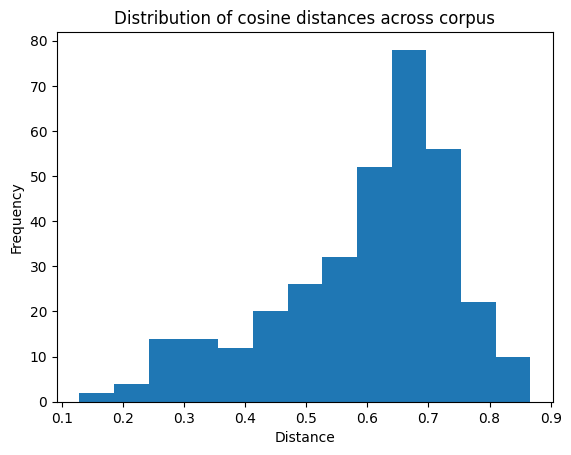


Smallest distance (most similar): 0.1291
  WHom_SermoLupi_A ↔ WHom_SermoLupi_B

Largest distance (most different): 0.8667
  WHom_SermoLupi_B ↔ BlHom_VII


In [ ]:
# Histogram of distance scores + most/least similar pairs
matrix = distance_calculator(counts, "cosine", corpus_metadata.index)

arr = matrix.values
arr_no_diag = arr[~np.eye(arr.shape[0], dtype=bool)]
arr_no_diag = arr_no_diag.flatten()
arr_no_diag.sort()

import matplotlib.pyplot as plt
plt.hist(arr_no_diag, bins=13)
plt.title("Distribution of cosine distances across corpus")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.show()

min_value = arr_no_diag[0]
min_location = (matrix == min_value)
row_idx, col_name = min_location.stack().idxmax()
print(f"\nSmallest distance (most similar): {min_value:.4f}\n  {row_idx} ↔ {col_name}")

max_value = arr_no_diag[-1]
max_location = (matrix == max_value)
row_idx, col_name = max_location.stack().idxmax()
print(f"\nLargest distance (most different): {max_value:.4f}\n  {row_idx} ↔ {col_name}")

In [ ]:
# reduce matrix dimensions
reduced_tsne = reduce_dimensions_tsne(matrix, perplexity=matrix.shape[0]**0.5, n_iter=5000, metric="euclidean", metadata=corpus_metadata)

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning:

'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.



In [ ]:
# visualize reduced dimensions

# adjust size column for visualization
size_min = 3
size_max = 70
size = (reduced_tsne["partial_length"] / reduced_tsne["partial_length"].max() * (size_max - size_min) + size_min).tolist()

# Label patch — relabel now that Scragg framing is dropped from the paper
reduced_tsne.loc["VHom_IV", "corpus_manual"] = "Anonymous_Vercelli"
reduced_tsne.loc["BHH_CCCC303", "corpus_manual"] = "Anonymous_Other"

# create figure
fig = px.scatter(reduced_tsne,
                 x="component 1", y="component 2",
                 size=size,
                 symbol="corpus_manual",
                 symbol_map={
                     "Wulfstan": "circle",
                     "Anonymous_Blickling": "diamond",
                     "Anonymous_Vercelli": "square",
                     "Anonymous_Other": "x",
                     "Aelfric": "circle"
                 },
                 color="author_group",
                 hover_data=["partial_length", "full_length", reduced_tsne.index])
fig.update_traces(marker=dict(line=dict(width=1, color='black')))
fig.show()

In [ ]:
# ── WORULDENDE: Whole-text TF-IDF with expanded vocabulary (max_features=300) ─────────────────
# Robustness check on LEMMATISED text — result locked to CSV so it's reproducible forever

vectorizer_v2 = TfidfVectorizer(
    input="content",
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b",
    max_features=300,
    stop_words=oe_stopwords
)

counts_v2 = vectorizer_v2.fit_transform(corpus_metadata["text"].tolist()).toarray()
vocab_v2 = vectorizer_v2.vocabulary_
switched_vocab_v2 = {v: k for k, v in vocab_v2.items()}
column_names_v2 = [switched_vocab_v2[x] for x in range(len(switched_vocab_v2))]
counts_df_v2 = pd.DataFrame(counts_v2, index=corpus_metadata.index, columns=column_names_v2)

print(f"\nVocabulary size (v2): {len(column_names_v2)} words")

# Distance matrix and t-SNE
matrix_v2 = distance_calculator(counts_v2, "cosine", corpus_metadata.index)

reduced_tsne_v2 = reduce_dimensions_tsne(matrix_v2,
                                          perplexity=matrix_v2.shape[0]**0.5,
                                          n_iter=5000,
                                          metric="euclidean",
                                          metadata=corpus_metadata)

# Label patch — relabel now that Scragg framing is dropped from the paper
reduced_tsne_v2.loc["VHom_IV", "corpus_manual"] = "Anonymous_Vercelli"
reduced_tsne_v2.loc["BHH_CCCC303", "corpus_manual"] = "Anonymous_Other"

# Lock this result in permanently, so it can never silently change again
reduced_tsne_v2.to_csv("Woruldende_wholetext_300_FINAL.csv")

# Visualise
fig_v2_wholetext = px.scatter(reduced_tsne_v2,
                 x="component 1", y="component 2",
                 color="author_group",
                 symbol="corpus_manual",
                 symbol_map={
                     "Wulfstan": "circle",
                     "Anonymous_Blickling": "diamond",
                     "Anonymous_Vercelli": "square",
                     "Anonymous_Other": "x",
                     "Aelfric": "circle"
                 },
                 hover_data=["corpus_manual", reduced_tsne_v2.index],
                 title="t-SNE: Whole-text Corpus, lemmatised (max_features=300)",
                 color_discrete_map={
                     "Wulfstan": "#636efa",
                     "Anonymous": "#EF553B",
                     "Aelfric": "#00cc96"
                 },
                 height=700)

fig_v2_wholetext.update_traces(marker=dict(size=10, line=dict(width=1, color='black')))
fig_v2_wholetext.show()

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning:

'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.




Vocabulary size (v2): 300 words


In [ ]:
def find_shared_tokens(df, text_ids):

  mini_df = df[df.index.isin(text_ids)].copy()
  mini_df = mini_df.loc[:, (mini_df != 0).all(axis=0)].copy()
  return mini_df.transpose()

In [ ]:
shared_tokens = find_shared_tokens(counts_df, ["BlHom_VII", "BlHom_X", "BlHom_XI", "VHom_II", "VHom_IV"])

In [ ]:
# ── COMBINED AUTHOR COMPARISON CHART ─────────────────────────
# Shows distinctive vocabulary for all three author groups side by side

from scipy.stats import zscore

# Get one representative text per group for comparison
# Use the full group TF-IDF scores averaged across texts

# Define groups
groups = {
    "Wulfstan": ["WHom_SermoLupi_A", "WHom_SermoLupi_B", "WHom_Antichrist", "WHom_SignsDoom"],
    "Anonymous": ["BlHom_II", "BlHom_IV", "BlHom_V", "BlHom_VII", "BlHom_X", "BlHom_XI",
                  "VHom_II", "VHom_IV", "VHom_V", "VHom_IX", "BHH_CCCC303"],
    "Aelfric": ["AECHom_I", "AECHom_XV", "AECHom_XXI", "AECHom_XL"]
}

# Calculate mean TF-IDF score per group
group_means = {}
for group_name, text_ids in groups.items():
    group_df = counts_df[counts_df.index.isin(text_ids)]
    group_means[group_name] = group_df.mean(axis=0)

# Build comparison dataframe
comparison_df = pd.DataFrame(group_means)

# For each group, find its TOP 10 most distinctive words
# (highest score in that group relative to the others)
top_words = set()
for group in groups.keys():
    other_groups = [g for g in groups.keys() if g != group]
    # Distinctiveness = this group's score minus mean of other groups
    distinctiveness = comparison_df[group] - comparison_df[other_groups].mean(axis=1)
    top_10 = distinctiveness.nlargest(10).index.tolist()
    top_words.update(top_10)

# Filter comparison to just these distinctive words
plot_df = comparison_df.loc[list(top_words)].reset_index()
plot_df.columns = ["word", "Wulfstan", "Anonymous", "Aelfric"]

# Melt for plotting
plot_melted = plot_df.melt(id_vars="word", var_name="author_group", value_name="tfidf_score")

# Plot
fig = px.bar(plot_melted,
             x="word",
             y="tfidf_score",
             color="author_group",
             barmode="group",
             title="Distinctive Vocabulary by Author Group",
             labels={"word": "Word", "tfidf_score": "Mean TF-IDF Score", "author_group": "Author Group"},
             color_discrete_map={"Wulfstan": "#636efa", "Anonymous": "#EF553B", "Aelfric": "#00cc96"},
             height=600,
             width=1400)

fig.update_layout(
    xaxis_tickangle=-45,
    font=dict(size=12),
    legend=dict(orientation="h", yanchor="bottom", y=1.02)
)
fig.show()

In [ ]:
# ── ALL THREE GROUPS SHARED TOKENS ON ONE CHART ──────────────

# Find words shared within each group
wulfstan_shared = find_shared_tokens(counts_df,
    ["WHom_SermoLupi_A", "WHom_SermoLupi_B", "WHom_Antichrist", "WHom_SignsDoom"])

anonymous_shared = find_shared_tokens(counts_df,
    ["BlHom_VII", "BlHom_X", "BlHom_XI", "VHom_II", "VHom_IV", "VHom_V", "VHom_IX", "BHH_CCCC303", "BlHom_II", "BlHom_IV", "BlHom_V"])

aelfric_shared = find_shared_tokens(counts_df,
    ["AECHom_I", "AECHom_XV", "AECHom_XXI", "AECHom_XL"])

# Get mean score per group for their shared words
wulfstan_mean = wulfstan_shared.mean(axis=1).rename("Wulfstan")
anonymous_mean = anonymous_shared.mean(axis=1).rename("Anonymous")
aelfric_mean = aelfric_shared.mean(axis=1).rename("Aelfric")

# Combine — keep only words that appear in at least one group's shared set
combined = pd.concat([wulfstan_mean, anonymous_mean, aelfric_mean], axis=1).fillna(0)

# Sort by total score so most important words appear first
combined["total"] = combined.sum(axis=1)
combined = combined.sort_values("total", ascending=False).drop(columns="total")
combined = combined.head(30)  # top 30 words

# Melt for plotting
combined_melted = combined.reset_index().melt(
    id_vars="index", var_name="Author Group", value_name="Mean TF-IDF Score")

# Plot
fig = px.bar(combined_melted,
             x="index",
             y="Mean TF-IDF Score",
             color="Author Group",
             barmode="group",
             title="Shared Vocabulary Compared Across All Three Author Groups",
             labels={"index": "Word"},
             color_discrete_map={"Wulfstan": "#636efa", "Anonymous": "#EF553B", "Aelfric": "#00cc96"},
             height=600,
             width=1400)

fig.update_layout(
    xaxis_tickangle=-45,
    font=dict(size=12),
    legend=dict(orientation="h", yanchor="bottom", y=1.02)
)
fig.show()

In [ ]:
# ── SHARED TOKENS SCATTER WITH LABELS ────────────────────────
fig = px.scatter(shared_tokens,
                 title="Shared Vocabulary Across Author Group",
                 height=500,
                 width=1200)

# Add word labels to every dot
fig.update_traces(
    mode="markers+text",
    textposition="top center",
    textfont=dict(size=10)
)

fig.update_layout(
    xaxis_tickangle=-45,
    margin=dict(b=100)
)
fig.show()

In [ ]:
# ── WORULDENDE: Generate chunks directly in Colab use instead of downloaded files ─────────────────
# UPDATED: now uses lemmatised (cf) text with fallback to unicode, matching the whole-text cell
# UPDATED AGAIN: normalises dryhten → drihten (Vercelli spelling variant)
import re, pandas as pd

def chunk_text(text, text_id, author_group, corpus_manual, chunk_size=500):
    words = [w for w in text.split() if w.strip()]
    chunks = []
    chunk_num = 1
    for i in range(0, len(words), chunk_size):
        chunk_words = words[i:i+chunk_size]
        if len(chunk_words) >= 200:
            chunks.append({
                'chunk_id': f"{text_id}_chunk{chunk_num}",
                'parent_text': text_id,
                'chunk_num': chunk_num,
                'author_group': author_group,
                'corpus_manual': corpus_manual,
                'language_manual': 'Old English',
                'text': ' '.join(chunk_words),
                'word_count': len(chunk_words)
            })
            chunk_num += 1
    return chunks

# Build chunks directly from corpus (already loaded in memory)
all_chunks = []
for df in corpus:
    text_id = df["text"].iloc[0]
    meta_row = metadata.loc[text_id] if text_id in metadata.index else None
    if meta_row is None:
        continue
    author_group = meta_row["author_group"]
    corpus_manual = meta_row["corpus_manual"]

    # Get full text using lemma (cf) where available, otherwise fall back to unicode
    words = []
    for _, row in df.iterrows():
        cf = str(row.get("cf", "")).strip()
        unicode_word = str(row.get("unicode", "")).strip()
        if cf and cf not in ["", "X", "nan", "UNK"]:
            cf_clean = "drihten" if cf.lower() == "dryhten" else cf.lower()
            words.append(cf_clean)
        elif unicode_word and unicode_word not in ["", "X", "nan"]:
            uw_clean = "drihten" if unicode_word.lower() == "dryhten" else unicode_word.lower()
            words.append(uw_clean)
    text = " ".join(words)

    chunks = chunk_text(text, text_id, author_group, corpus_manual)
    all_chunks.extend(chunks)
    print(f"✓ {text_id}: {len(chunks)} chunks")

chunks_df = pd.DataFrame(all_chunks)
chunks_meta = pd.DataFrame([{
    'text_id': c['chunk_id'],
    'author_group': c['author_group'],
    'corpus_manual': c['corpus_manual'],
    'language_manual': c['language_manual'],
    'parent_text': c['parent_text'],
    'chunk_num': c['chunk_num'],
    'word_count': c['word_count']
} for c in all_chunks]).set_index('text_id')

print(f"\nTotal chunks: {len(all_chunks)}")
print(chunks_meta["author_group"].value_counts())

# Vectorize
chunk_vectorizer = TfidfVectorizer(
    input="content",
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b",
    max_features=100,
    stop_words=oe_stopwords
)

chunk_counts = chunk_vectorizer.fit_transform(
    chunks_df["text"].tolist()).toarray()
chunk_vocab = chunk_vectorizer.vocabulary_
chunk_switched = {v: k for k, v in chunk_vocab.items()}
chunk_cols = [chunk_switched[x] for x in range(len(chunk_switched))]
chunk_counts_df = pd.DataFrame(chunk_counts,
                                index=chunks_df["chunk_id"].tolist(),
                                columns=chunk_cols)

print(f"✓ Vectorized: {chunk_counts.shape[0]} chunks, {chunk_counts.shape[1]} features")

# Distance matrix and t-SNE
chunk_matrix = distance_calculator(chunk_counts, "cosine", chunk_counts_df.index)

reduced_chunks = reduce_dimensions_tsne(chunk_matrix,
                                         perplexity=chunk_matrix.shape[0]**0.5,
                                         n_iter=5000,
                                         metric="euclidean",
                                         metadata=chunks_meta)

# Label patch — relabel now that Scragg framing is dropped from the paper
chunk_mask_vhomiv = reduced_chunks["parent_text"] == "VHom_IV"
chunk_mask_bhh = reduced_chunks["parent_text"] == "BHH_CCCC303"
reduced_chunks.loc[chunk_mask_vhomiv, "corpus_manual"] = "Anonymous_Vercelli"
reduced_chunks.loc[chunk_mask_bhh, "corpus_manual"] = "Anonymous_Other"

# Visualise
fig = px.scatter(reduced_chunks,
                 x="component 1", y="component 2",
                 color="author_group",
                 symbol="corpus_manual",
                 symbol_map={
                     "Wulfstan": "circle",
                     "Anonymous_Blickling": "diamond",
                     "Anonymous_Vercelli": "square",
                     "Anonymous_Other": "x",
                     "Aelfric": "circle"
                 },
                 hover_data=["parent_text", "chunk_num", reduced_chunks.index],
                 title="t-SNE: 500-word Chunks Across All Texts (lemmatised)",
                 color_discrete_map={
                     "Wulfstan": "#636efa",
                     "Anonymous": "#EF553B",
                     "Aelfric": "#00cc96"
                 },
                 height=700)

fig.update_traces(marker=dict(size=10, line=dict(width=1, color='black')))
fig.show()

✓ WHom_SermoLupi_A: 4 chunks
✓ WHom_SermoLupi_B: 4 chunks
✓ WHom_Antichrist: 1 chunks
✓ WHom_SignsDoom: 2 chunks
✓ BlHom_II: 4 chunks
✓ BlHom_IV: 6 chunks
✓ BlHom_V: 4 chunks
✓ BlHom_VII: 5 chunks
✓ BlHom_X: 3 chunks
✓ BlHom_XI: 6 chunks
✓ VHom_II: 3 chunks
✓ VHom_IV: 8 chunks
✓ VHom_V: 4 chunks
✓ VHom_IX: 4 chunks
✓ BHH_CCCC303: 2 chunks
✓ AECHom_I: 6 chunks
✓ AECHom_XV: 3 chunks
✓ AECHom_XXI: 5 chunks
✓ AECHom_XL: 3 chunks

Total chunks: 77
author_group
Anonymous    49
Aelfric      17
Wulfstan     11
Name: count, dtype: int64
✓ Vectorized: 77 chunks, 100 features


/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning:

'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.



In [ ]:
# ── WORULDENDE: Chunk-level t-SNE with expanded vocabulary (max_features=300) max_features=300 robustness check ─────────────────
# Tests whether the upper-cluster convergence (Sophonias/dæg/helle chunks) survives
# with a less restrictive TF-IDF feature cap, or whether it was a max_features=100 artifact

chunk_vectorizer_v2 = TfidfVectorizer(
    input="content",
    lowercase=True,
    token_pattern=r"(?u)\b\w+\b",
    max_features=300,
    stop_words=oe_stopwords
)

chunk_counts_v2 = chunk_vectorizer_v2.fit_transform(
    chunks_df["text"].tolist()).toarray()
chunk_vocab_v2 = chunk_vectorizer_v2.vocabulary_
chunk_switched_v2 = {v: k for k, v in chunk_vocab_v2.items()}
chunk_cols_v2 = [chunk_switched_v2[x] for x in range(len(chunk_switched_v2))]
chunk_counts_df_v2 = pd.DataFrame(chunk_counts_v2,
                                index=chunks_df["chunk_id"].tolist(),
                                columns=chunk_cols_v2)

print(f"✓ Vectorized (v2, max_features=300): {chunk_counts_v2.shape[0]} chunks, {chunk_counts_v2.shape[1]} features")

# Distance matrix and t-SNE
chunk_matrix_v2 = distance_calculator(chunk_counts_v2, "cosine", chunk_counts_df_v2.index)

reduced_chunks_v2 = reduce_dimensions_tsne(chunk_matrix_v2,
                                         perplexity=chunk_matrix_v2.shape[0]**0.5,
                                         n_iter=5000,
                                         metric="euclidean",
                                         metadata=chunks_meta)

# Label patch — relabel now that Scragg framing is dropped from the paper
chunk_mask_vhomiv = reduced_chunks_v2["parent_text"] == "VHom_IV"
chunk_mask_bhh = reduced_chunks_v2["parent_text"] == "BHH_CCCC303"
reduced_chunks_v2.loc[chunk_mask_vhomiv, "corpus_manual"] = "Anonymous_Vercelli"
reduced_chunks_v2.loc[chunk_mask_bhh, "corpus_manual"] = "Anonymous_Other"

# Visualise
fig_v2_chunks = px.scatter(reduced_chunks_v2,
                 x="component 1", y="component 2",
                 color="author_group",
                 symbol="corpus_manual",
                 symbol_map={
                     "Wulfstan": "circle",
                     "Anonymous_Blickling": "diamond",
                     "Anonymous_Vercelli": "square",
                     "Anonymous_Other": "x",
                     "Aelfric": "circle"
                 },
                 hover_data=["parent_text", "chunk_num", reduced_chunks_v2.index],
                 title="t-SNE: 500-word Chunks (max_features=300)",
                 color_discrete_map={
                     "Wulfstan": "#636efa",
                     "Anonymous": "#EF553B",
                     "Aelfric": "#00cc96"
                 },
                 height=700)

fig_v2_chunks.update_traces(marker=dict(size=10, line=dict(width=1, color='black')))
fig_v2_chunks.show()

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning:

Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['unk', 'x'] not in stop_words.

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning:

'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.



✓ Vectorized (v2, max_features=300): 77 chunks, 300 features


In [ ]:
chunk_ids_to_check = [
    "AECHom_XL_chunk3", "AECHom_I_chunk6",
    "BHH_CCCC303_chunk2", "VHom_II_chunk1",
    "VHom_IV_chunk4", "VHom_IV_chunk5", "VHom_IV_chunk7"
]

for cid in chunk_ids_to_check:
    row = chunks_df[chunks_df["chunk_id"] == cid]
    if not row.empty:
        print(f"\n=== {cid} ===")
        print(row["text"].values[0])
    else:
        print(f"\n=== {cid} NOT FOUND — check exact id/column name ===")


=== AECHom_XL_chunk3 ===
drihten to iudeiscre mægðe and heora cynn ne gewít þurh ateorunge ærðan ðe þes middangeard geendað be ðisum andgite cwæð se apostol paulus þæt drihten sylf astihð of heofon on stemne þæs heahengles and mid god byme and ða deadan ærest arisan syððan we ðe lybbað and on lichaman beoð gemette beoð gelæhte forð mid þam oðrum on wolcnum togeanes crist and we swa symle syððan mid god beoð frefriað eów mid þisum wordum eac on ðisum andgite geðwærlæhð se godspellere matheus þisum wordum drihten asent his engel mid byme and micelre stemne and hí gaderiað his gecorenan fram feower windum of eallum eorðlicum gemærum oð ða heálican heofon se apostol cwæð we ðe lybbað ne mænde he hine sylfne mid þam worde ac ða ðe on lif þurhwuniað oþ geendunge þyssere woruld mid þam is eac geswutelod þæt mancynn mid ealle ne ateorað ær ðære geendunge ac hí habbað hwæðere sceortne deaþ þa ðe þonne on lif gemette beoð forðan ðe heofonlic fyr ofergæð ealne middangeard mid anum bryne and ða d

In [ ]:
for cid in ["AECHom_XL_chunk3", "BHH_CCCC303_chunk2", "VHom_IX_chunk4", "VHom_II_chunk2"]:
    print(f"\n=== {cid} top TF-IDF terms ===")
    row = chunk_counts_df.loc[cid]
    print(row.sort_values(ascending=False).head(15))


=== AECHom_XL_chunk3 top TF-IDF terms ===
fyr            0.564627
dæg            0.518553
heofon         0.292963
cwæð           0.278205
eorþe          0.198374
fram           0.153576
god            0.145327
mine           0.144548
crist          0.142064
drihten        0.124642
symle          0.124248
buton          0.111282
seo            0.094710
middangeard    0.087962
eac            0.086705
Name: AECHom_XL_chunk3, dtype: float64

=== BHH_CCCC303_chunk2 top TF-IDF terms ===
dæg        0.833435
fyr        0.238215
butan      0.213876
heofon     0.164801
synn       0.164801
hæfde      0.142584
hell       0.134539
magon      0.119004
ende       0.108189
lif        0.096165
drihten    0.093487
woruld     0.084920
naman      0.074291
a          0.071292
habban     0.069893
Name: BHH_CCCC303_chunk2, dtype: float64

=== VHom_IX_chunk4 top TF-IDF terms ===
butan     0.514312
rice      0.387087
sy        0.353257
sio       0.264392
mycel     0.207983
ofer      0.200496
eal       0.17806

In [ ]:
# ── WORULDENDE: Five-way comparison — splitting Anonymous into Blickling vs Vercelli ─────────────────
# Ad-hoc follow-up: does Blickling actually differ from Vercelli in vocabulary,
# or just in t-SNE position? Reuses the final lemmatised, max_features=300 whole-text result.

five_groups = {
    "Wulfstan": ["WHom_SermoLupi_A", "WHom_SermoLupi_B", "WHom_Antichrist", "WHom_SignsDoom"],
    "Blickling": ["BlHom_II", "BlHom_IV", "BlHom_V", "BlHom_VII", "BlHom_X", "BlHom_XI"],
    "Vercelli": ["VHom_II", "VHom_IV", "VHom_V", "VHom_IX"],
    "Other_anonymous": ["BHH_CCCC303"],   # single text — shown for completeness, not statistically meaningful alone
    "Aelfric": ["AECHom_I", "AECHom_XV", "AECHom_XXI", "AECHom_XL"]
}

# Mean TF-IDF score per group
five_group_means = {}
for group_name, text_ids in five_groups.items():
    group_df = counts_df_v2[counts_df_v2.index.isin(text_ids)]
    five_group_means[group_name] = group_df.mean(axis=0)

five_comparison_df = pd.DataFrame(five_group_means)

# Top 8 most distinctive words per group
five_top_words = set()
for group in five_groups.keys():
    other_groups = [g for g in five_groups.keys() if g != group]
    distinctiveness = five_comparison_df[group] - five_comparison_df[other_groups].mean(axis=1)
    five_top_words.update(distinctiveness.nlargest(8).index.tolist())

five_plot_df = five_comparison_df.loc[list(five_top_words)].reset_index()
five_plot_df.columns = ["word", "Wulfstan", "Blickling", "Vercelli", "Other_anonymous", "Aelfric"]
five_plot_melted = five_plot_df.melt(id_vars="word", var_name="group", value_name="tfidf_score")

fig_five = px.bar(five_plot_melted,
             x="word", y="tfidf_score", color="group", barmode="group",
             title="Distinctive Vocabulary: Blickling vs Vercelli (Wulfstan/Aelfric shown for reference)",
             labels={"word": "Word", "tfidf_score": "Mean TF-IDF Score", "group": "Group"},
             color_discrete_map={
                 "Wulfstan": "#636efa",
                 "Blickling": "#EF553B",
                 "Vercelli": "#FFA15A",
                 "Other_anonymous": "#AB63FA",
                 "Aelfric": "#00cc96"
             },
             height=600, width=1400)

fig_five.update_layout(xaxis_tickangle=-45, font=dict(size=12),
                        legend=dict(orientation="h", yanchor="bottom", y=1.02))
fig_five.show()

# Direct numeric check — does this confirm Vercelli sits closer to everyone else?
from scipy.spatial.distance import cosine

print(f"Blickling vs Vercelli: {cosine(five_comparison_df['Blickling'], five_comparison_df['Vercelli']):.4f}")
print(f"Blickling vs Wulfstan: {cosine(five_comparison_df['Blickling'], five_comparison_df['Wulfstan']):.4f}")
print(f"Blickling vs Aelfric:  {cosine(five_comparison_df['Blickling'], five_comparison_df['Aelfric']):.4f}")
print(f"Vercelli vs Wulfstan:  {cosine(five_comparison_df['Vercelli'], five_comparison_df['Wulfstan']):.4f}")
print(f"Vercelli vs Aelfric:   {cosine(five_comparison_df['Vercelli'], five_comparison_df['Aelfric']):.4f}")

Blickling vs Vercelli: 0.5261
Blickling vs Wulfstan: 0.6311
Blickling vs Aelfric:  0.5762
Vercelli vs Wulfstan:  0.6199
Vercelli vs Aelfric:   0.4544


In [ ]:
mean_distances = matrix_v2.mean(axis=1).sort_values(ascending=False)
print(mean_distances)

text_id
WHom_SermoLupi_B    0.724552
AECHom_XV           0.718953
BHH_CCCC303         0.695371
WHom_Antichrist     0.680462
VHom_IX             0.671938
WHom_SermoLupi_A    0.669741
AECHom_XL           0.641327
WHom_SignsDoom      0.638095
VHom_II             0.628969
VHom_IV             0.625343
VHom_V              0.621452
BlHom_VII           0.617757
BlHom_II            0.611492
AECHom_I            0.608580
BlHom_V             0.606258
AECHom_XXI          0.603218
BlHom_XI            0.602282
BlHom_X             0.597072
BlHom_IV            0.596403
dtype: float64


In [ ]:
mean_distance_outside_group = {}
for text_id in corpus_metadata.index:
    own_group = corpus_metadata.loc[text_id, "author_group"]
    other_texts = corpus_metadata[corpus_metadata["author_group"] != own_group].index
    mean_distance_outside_group[text_id] = matrix_v2.loc[text_id, other_texts].mean()

result = pd.Series(mean_distance_outside_group).sort_values(ascending=False)
print(result)

# Also show group-level averages
group_avg = result.groupby(corpus_metadata["author_group"]).mean()
print("\nMean distance-to-other-groups, by group:")
print(group_avg.sort_values(ascending=False))

WHom_SermoLupi_B    0.815880
AECHom_XV           0.799383
BlHom_VII           0.785325
BlHom_II            0.770270
VHom_IX             0.768690
WHom_SermoLupi_A    0.763832
BlHom_V             0.762945
BHH_CCCC303         0.749711
WHom_Antichrist     0.743569
BlHom_XI            0.742894
VHom_II             0.731132
BlHom_IV            0.722013
WHom_SignsDoom      0.707924
AECHom_XL           0.705165
VHom_IV             0.704093
BlHom_X             0.686569
AECHom_XXI          0.678104
AECHom_I            0.664254
VHom_V              0.659329
dtype: float64

Mean distance-to-other-groups, by group:
author_group
Wulfstan     0.757801
Anonymous    0.734816
Aelfric      0.711727
dtype: float64


In [ ]:
print(counts_df_v2.loc[:, "heofon"] if "heofon" in counts_df_v2.columns else "not in vocab")

text_id
WHom_SermoLupi_A    0.000000
WHom_SermoLupi_B    0.000000
WHom_Antichrist     0.053345
WHom_SignsDoom      0.037229
BlHom_VII           0.086328
BlHom_X             0.020344
BlHom_XI            0.091470
BlHom_II            0.000000
BlHom_IV            0.039177
BlHom_V             0.000000
VHom_II             0.094825
VHom_IV             0.032787
VHom_V              0.119926
VHom_IX             0.012897
BHH_CCCC303         0.132112
AECHom_I            0.035137
AECHom_XV           0.078257
AECHom_XXI          0.161095
AECHom_XL           0.145723
Name: heofon, dtype: float64


In [ ]:
# Save charts using write_html instead
fig_heatmap = px.imshow(matrix)
fig_heatmap.update_layout(autosize=False, width=1500, height=1500)
fig_heatmap.write_html("Woruldende_heatmap_distances.html")

size = (reduced_tsne["partial_length"] / reduced_tsne["partial_length"].max() * (70 - 3) + 3).tolist()
fig_tsne = px.scatter(reduced_tsne, x="component 1", y="component 2", size=size,
                      symbol="corpus_manual", color="author_group",
                      hover_data=["partial_length", "full_length", reduced_tsne.index])
fig_tsne.update_traces(marker=dict(line=dict(width=1, color='black')))
fig_tsne.write_html("Woruldende_tSNE_author_groups.html")

print("Files saved as HTML!")

*This notebook was created by [Avital Romach](https://github.com/ARomach), with additional code and text by [Eliese-Sophia Lincke](https://www.geschkult.fu-berlin.de/e/aegyptologie/personen/Professorinnen-und-Professoren/Lincke/index.html), [Shai Gordin](https://digitalpasts.github.io/) and [Daniel A. Werning](https://www.bbaw.de/die-akademie/mitarbeiterinnen-mitarbeiter/werning-daniel) in Spring 2024 for the course [Ancient Language Processing](https://digitalpasts.github.io/ALP-course/). Code can be reused under a [CC-BY 4.0](https://creativecommons.org/licenses/by/4.0/)*